In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve

Iterations: 104
Temperature distribution:
[[29.92646534 29.04411316 25.22058507 16.69117489  0.        ]
 [30.80881905 30.51470206 27.57352671 20.77205747 10.        ]
 [32.27940859 34.63235024 33.78676279 28.82352846 20.        ]
 [29.04411606 41.94852806 44.1176461  40.73529364 30.        ]
 [ 0.         60.         60.         60.         30.        ]]


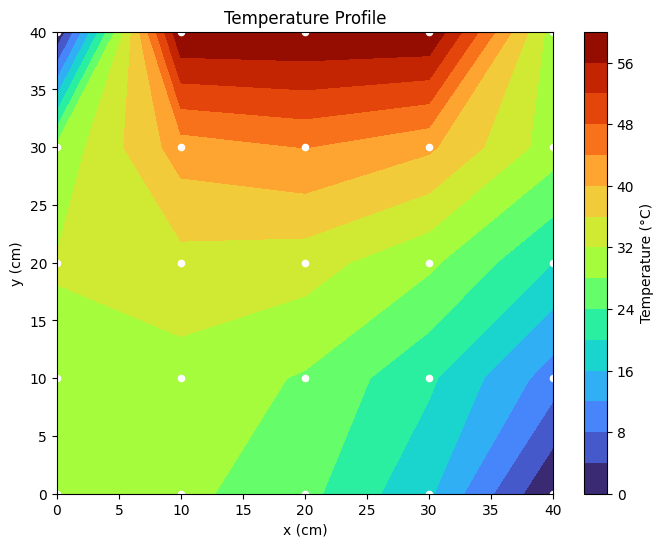

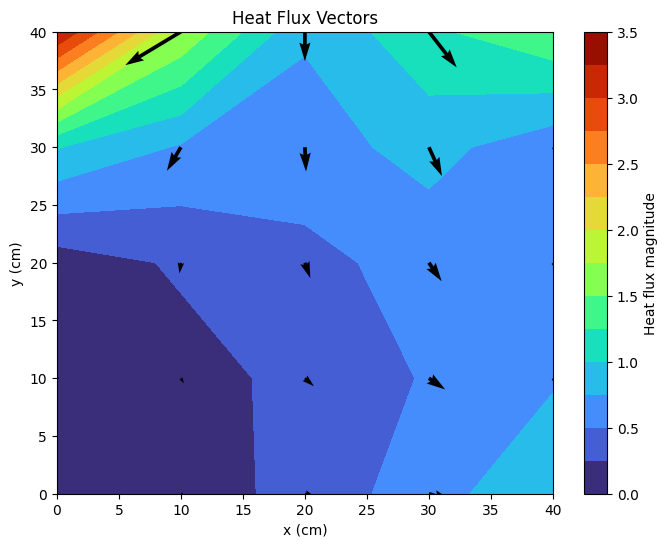

In [2]:
# Grid parameters
Lx = 40
Ly = 40
dx = 10
dy = 10

x = np.arange(0, Lx + dx, dx)
y = np.arange(0, Ly + dy, dy)

nx = len(x)
ny = len(y)

# Temperature grid
T = np.zeros((ny, nx))

T[-1, :] = [0, 60, 60, 60, 30]


T[:, -1] = [0, 10, 20, 30, 30]

tol = 1e-6
max_iter = 100000

for iteration in range(max_iter):
    T_old = T.copy()

    for j in range(ny):
        for i in range(nx):

            if j == ny - 1 or i == nx - 1:
                continue
            if i > 0 and j > 0:
                T[j, i] = (
                    T[j, i+1] + T[j, i-1]
                    + T[j+1, i] + T[j-1, i]
                ) / 4

            elif i == 0 and j > 0:
                T[j, i] = (
                    2*T[j, i+1] + T[j+1, i] + T[j-1, i]
                ) / 4

            elif j == 0 and i > 0:
                T[j, i] = (
                    T[j, i+1] + T[j, i-1] + 2*T[j+1, i]
                ) / 4

            elif i == 0 and j == 0:
                T[j, i] = (
                    2*T[j, i+1] + 2*T[j+1, i]
                ) / 4

    if np.max(np.abs(T - T_old)) < tol:
        break

print("Iterations:", iteration + 1)
print("Temperature distribution:")
print(T)

dTdy, dTdx = np.gradient(T, dy, dx)

k = 0.49
qx = -k * dTdx
qy = -k * dTdy

X, Y = np.meshgrid(x, y)


plt.figure(figsize=(8, 6))
contour = plt.contourf(X, Y, T, levels=15, cmap='turbo')
plt.colorbar(contour, label='Temperature (°C)')
plt.scatter(X, Y, color='white', s=20)
plt.xlabel('x (cm)')
plt.ylabel('y (cm)')
plt.title('Temperature Profile')
plt.show()

plt.figure(figsize=(8, 6))
contour = plt.contourf(X, Y, np.sqrt(qx**2 + qy**2),
                       levels=15, cmap='turbo')
plt.colorbar(contour, label='Heat flux magnitude')

plt.quiver(X, Y, qx, qy, color='black')
plt.xlabel('x (cm)')
plt.ylabel('y (cm)')
plt.title('Heat Flux Vectors')
plt.show()